# Phase I: Model behavior on AI-generated vs. human-written text

Model: `facebook/roberta-hate-speech-dynabench-r4-target`  
Datasets: ToxiGen (AI-generated) and Measuring Hate Speech (human-written), 5 target groups each, balanced toxic / non-toxic.

## Load the datasets

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

folder = os.getcwd()
ai_df = pd.read_csv(os.path.join(folder, "toxigen_processed_scored.csv"))
human_df = pd.read_csv(os.path.join(folder, "mhs_5groups_2500_results.csv"))

print("AI-generated:", ai_df.shape)
print("Human-written:", human_df.shape)

AI-generated: (2300, 17)
Human-written: (2500, 17)


## 1. Accuracy per dataset and group

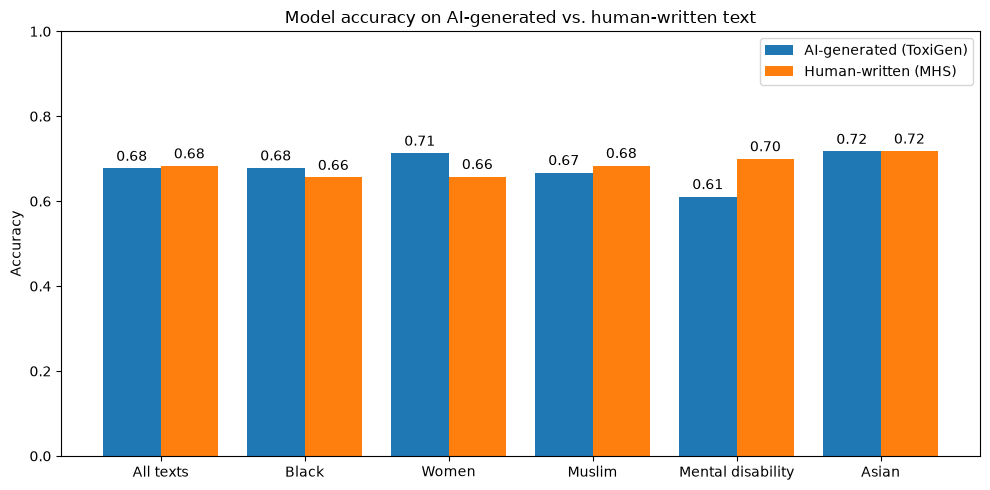

In [2]:
def get_accuracy(df):
  """Returns the share of texts where the model's prediction is correct."""
  return (df["true_label"] == df["pred_label"]).mean()


groups = ["black", "women", "muslim", "mental_dis", "asian"]
labels = ["All texts", "Black", "Women", "Muslim", "Mental disability",
          "Asian"]

# Accuracy for all texts first, then for each group.
ai_acc = [get_accuracy(ai_df)]
human_acc = [get_accuracy(human_df)]
for group in groups:
  ai_acc.append(get_accuracy(ai_df[ai_df["target_group"] == group]))
  human_acc.append(get_accuracy(human_df[human_df["target_group"] == group]))

# Two bars per category: AI on the left, human on the right.
ai_x, human_x = [], []
for i in range(len(labels)):
  ai_x.append(i - 0.2)
  human_x.append(i + 0.2)

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(ai_x, ai_acc, width=0.4, color="tab:blue",
               label="AI-generated (ToxiGen)")
bars2 = ax.bar(human_x, human_acc, width=0.4, color="tab:orange",
               label="Human-written (MHS)")
ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Model accuracy on AI-generated vs. human-written text")
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig(os.path.join(folder, "accuracy_chart.png"), dpi=200)
plt.show()

## 2. Confusion matrices

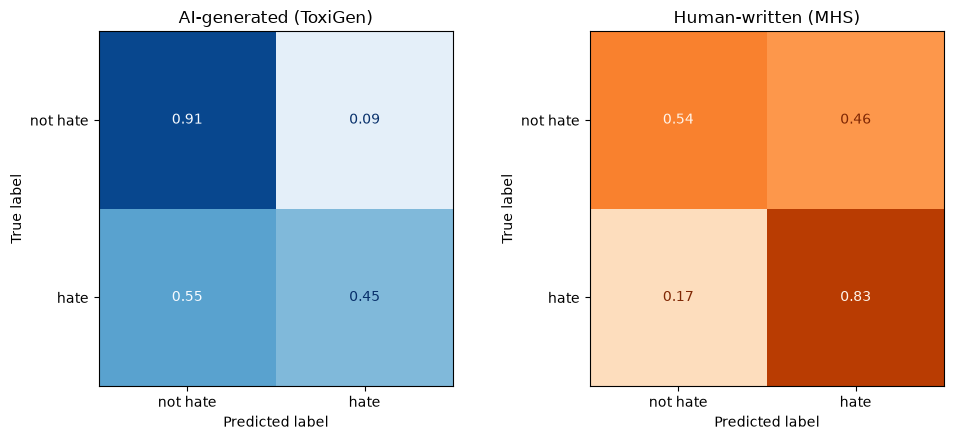

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ConfusionMatrixDisplay.from_predictions(
    ai_df["true_label"], ai_df["pred_label"], normalize="true",
    display_labels=["not hate", "hate"], cmap="Blues", values_format=".2f",
    colorbar=False, im_kw={"vmin": 0, "vmax": 1}, ax=axes[0])
axes[0].set_title("AI-generated (ToxiGen)")

ConfusionMatrixDisplay.from_predictions(
    human_df["true_label"], human_df["pred_label"], normalize="true",
    display_labels=["not hate", "hate"], cmap="Oranges", values_format=".2f",
    colorbar=False, im_kw={"vmin": 0, "vmax": 1}, ax=axes[1])
axes[1].set_title("Human-written (MHS)")

plt.tight_layout()
plt.savefig(os.path.join(folder, "confusion_matrices.png"), dpi=200)
plt.show()

## 3. Butterfly chart: False Negative Rate vs. False Positive Rate

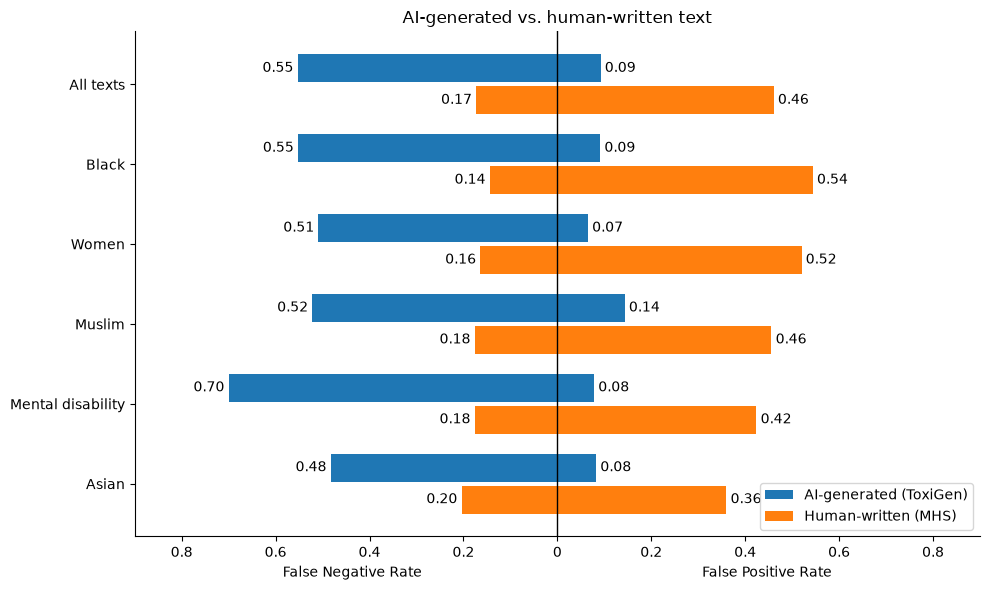

In [4]:
def get_rates(df):
  fn_rate = 1 - df[df["true_label"] == 1]["pred_label"].mean()
  fp_rate = df[df["true_label"] == 0]["pred_label"].mean()
  return fn_rate, fp_rate


groups = ["asian", "mental_dis", "muslim", "women", "black"]
labels = ["Asian", "Mental disability", "Muslim", "Women", "Black",
          "All texts"]

# Rates for each group, and for all texts at the end.
ai_fn, ai_fp, human_fn, human_fp = [], [], [], []
for group in groups:
  fn, fp = get_rates(ai_df[ai_df["target_group"] == group])
  ai_fn.append(fn)
  ai_fp.append(fp)
  fn, fp = get_rates(human_df[human_df["target_group"] == group])
  human_fn.append(fn)
  human_fp.append(fp)

fn, fp = get_rates(ai_df)
ai_fn.append(fn)
ai_fp.append(fp)
fn, fp = get_rates(human_df)
human_fn.append(fn)
human_fp.append(fp)

# Each row has two bars: AI slightly above, human slightly below.
rows = range(len(labels))
ai_y, human_y = [], []
ai_fn_left, human_fn_left = [], []
ai_fn_text, ai_fp_text, human_fn_text, human_fp_text = [], [], [], []
for i in rows:
  ai_y.append(i + 0.2)
  human_y.append(i - 0.2)
  ai_fn_left.append(-ai_fn[i])
  human_fn_left.append(-human_fn[i])
  ai_fn_text.append(f"{ai_fn[i]:.2f}")
  ai_fp_text.append(f"{ai_fp[i]:.2f}")
  human_fn_text.append(f"{human_fn[i]:.2f}")
  human_fp_text.append(f"{human_fp[i]:.2f}")

fig, ax = plt.subplots(figsize=(10, 6))

# FN rates are drawn to the left (negative), FP rates to the right.
bars1 = ax.barh(ai_y, ai_fn_left, height=0.35, color="tab:blue",
                label="AI-generated (ToxiGen)")
bars2 = ax.barh(ai_y, ai_fp, height=0.35, color="tab:blue")
bars3 = ax.barh(human_y, human_fn_left, height=0.35, color="tab:orange",
                label="Human-written (MHS)")
bars4 = ax.barh(human_y, human_fp, height=0.35, color="tab:orange")

# Write the rate next to each bar.
ax.bar_label(bars1, labels=ai_fn_text, padding=3)
ax.bar_label(bars2, labels=ai_fp_text, padding=3)
ax.bar_label(bars3, labels=human_fn_text, padding=3)
ax.bar_label(bars4, labels=human_fp_text, padding=3)

ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(rows)
ax.set_yticklabels(labels)
ax.set_xlim(-0.9, 0.9)
ax.set_xticks([-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8])
ax.set_xticklabels(["0.8", "0.6", "0.4", "0.2", "0", "0.2", "0.4", "0.6",
                    "0.8"])
ax.set_xlabel("False Negative Rate" + " " * 70 + "False Positive Rate")
ax.set_title("AI-generated vs. human-written "
             "text")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(folder, "butterfly_chart.png"), dpi=200)
plt.show()